# Projet 2 : exploration des données

Dataset Roboflow *football-players-detection*, version 12 (372 images en 1280 x 1280 px), avec gardien fusionné dans joueur : 3 classes (ballon, joueur, arbitre).

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path("..").resolve()))   # rend le dossier projet2_foot importable
from IPython.display import Image, display
from src.explore import load_boxes, fig_sizes, fig_example, FIG

df = load_boxes()
df.head()

,split,image,cls,x,y,w,h,w_orig,h_orig,side_640,side_1280
0,train,08fd33_0_10_png.rf.a6b65fe79fde62de2bfb62ce60e...,ball,0.548047,0.466016,0.005078,0.012109,9.75,13.078125,5.018715,10.037430
1,train,08fd33_0_10_png.rf.a6b65fe79fde62de2bfb62ce60e...,referee,0.362891,0.213672,0.014453,0.037891,27.75,40.921875,14.977066,29.954132
2,train,08fd33_0_10_png.rf.a6b65fe79fde62de2bfb62ce60e...,player,0.417578,0.248047,0.014453,0.033203,27.75,35.859375,14.020075,28.040150
3,train,08fd33_0_10_png.rf.a6b65fe79fde62de2bfb62ce60e...,player,0.680859,0.325391,0.018750,0.050781,36.00,54.843750,19.748418,39.496835
4,train,08fd33_0_10_png.rf.a6b65fe79fde62de2bfb62ce60e...,player,0.745703,0.341797,0.013672,0.055469,26.25,59.906250,17.624557,35.249113


## Nombre d'objets par split et par classe

In [2]:
counts = df.pivot_table(index="split", columns="cls", values="x", aggfunc="count").reindex(["train", "valid", "test"])
counts["images"] = [df[df.split == s].image.nunique() for s in counts.index]
counts

cls,ball,player,referee,images
split,,,,
train,258,6185,690,298
valid,45,1012,117,49
test,24,518,56,25


## Images sans ballon

In [3]:
balls = df.groupby(["split", "image"]).cls.apply(lambda s: (s == "ball").sum())
print("Images sans ballon :", int((balls == 0).sum()), "sur", len(balls))
print("Objets par image (médiane) :", df.groupby("image").size().median())

Images sans ballon : 47 sur 372
Objets par image (médiane) : 24.0


## Taille des objets

Les images Roboflow sont étirées de 1920 x 1080 à 1280 x 1280. `w_orig` et `h_orig` sont les tailles dans la vidéo d'origine, `side_640` et `side_1280` le côté moyen vu par YOLO selon la résolution d'entrée.

In [4]:
stats = df.groupby("cls")[["w_orig", "h_orig", "side_640", "side_1280"]].median().round(1)
stats["part < 8 px à 640"] = df.groupby("cls").side_640.apply(lambda s: (s < 8).mean()).round(3)
stats

,w_orig,h_orig,side_640,side_1280,part < 8 px à 640
cls,,,,,
ball,11.2,11.8,5.0,10.1,0.979
player,24.0,54.0,15.9,31.7,0.001
referee,21.0,48.9,14.3,28.6,0.009


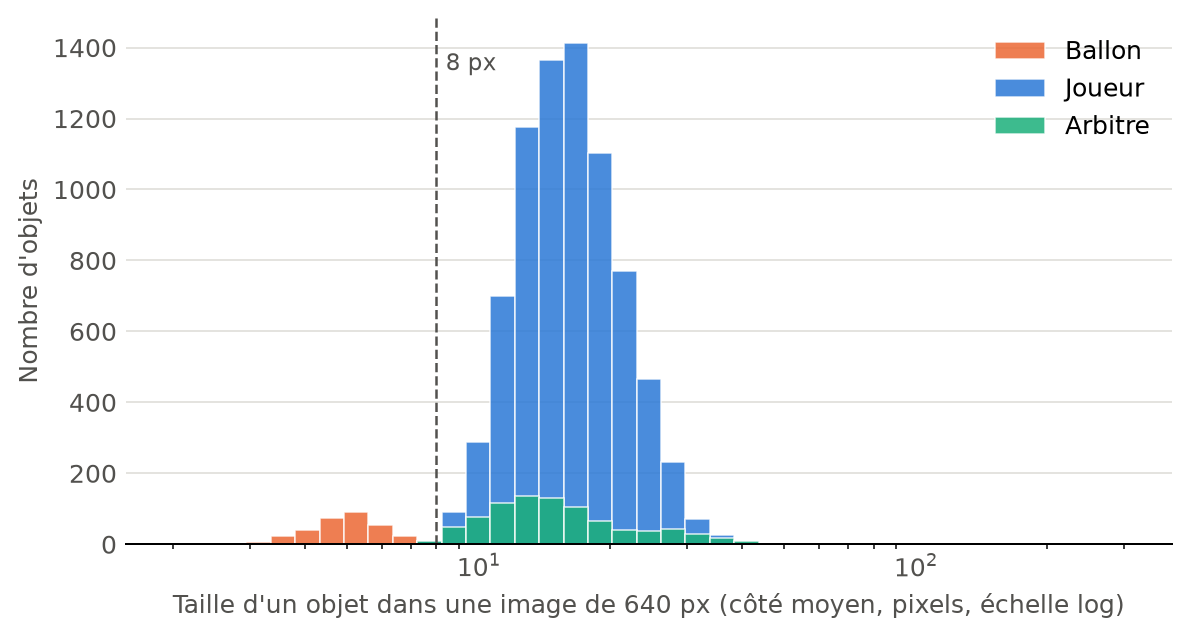

In [5]:
fig_sizes(df, FIG / "tailles_objets.png")
display(Image(FIG / "tailles_objets.png", width=700))

## Une image annotée

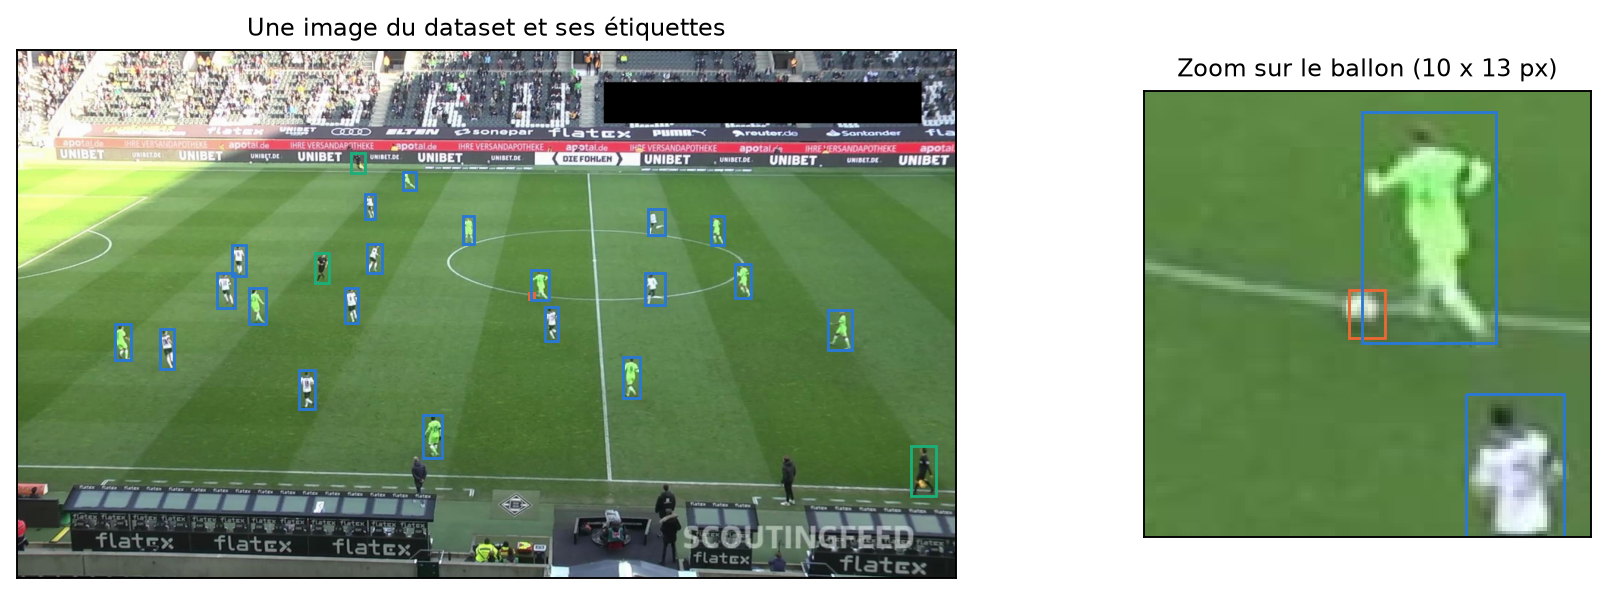

In [6]:
fig_example(df, FIG / "exemple_annote.png")
display(Image(FIG / "exemple_annote.png", width=900))

**À retenir :** le ballon fait environ 5 px de côté à 640 px (98 % des ballons sous 8 px), contre 16 px pour un joueur. D'où les essais à 1280 px et avec SAHI.